In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(r'D:\data analytics\Python\Supply chain analysis\data\Cleaned_dataco.csv')

In [4]:
Total_sales = df['Sales'].sum()
print("Total sales : ",Total_sales)

Total sales :  36784735.01337984


### Overall Business Performance

The dataset generated approximately **$36.78 million in total sales** across 180,519 order-item records.

In [5]:
Total_profit = df['Order Profit Per Order'].sum()
print("Total profit : ",Total_profit)

Total profit :  3966902.974050357


In [6]:
Profit_margin = (Total_profit/Total_sales)*100

In [7]:
print("Profit margin(%): ",Profit_margin)

Profit margin(%):  10.78410099354382


In [8]:
Total_orders = df['Order Id'].nunique()
print("Total order count: ",Total_orders)

Total order count:  65752


In [9]:
Total_customers = df["Customer Id"].nunique()

print("Total Customers:", Total_customers)

Total Customers: 20652




The cleaned dataset contains 180,519 order-item records, representing 65,752 unique orders and 20,652 unique customers.

The business generated approximately **$36.78 million in sales** and **$3.97 million in profit**, resulting in an overall profit margin of approximately **10.78%**.

In [10]:
average_order_value = (Total_sales/Total_orders)
print("Average Order Value: ",average_order_value)

Average Order Value:  559.4466330055335


### Average Order Value

The Average Order Value (AOV) was calculated by dividing total sales by the number of unique orders.

The dataset has an average order value of approximately **$559.45**, meaning each order generated around $559 in sales on average.

### Yearly Sales and Profit

In [11]:
yearly_performance = df.groupby("order year").agg(Total_sales = ("Sales","sum"),
Total_profit = ("Order Profit Per Order","sum")).reset_index()
yearly_performance

,order year,Total_sales,Total_profit
0,2015,1.234083e+07,1.318857e+06
1,2016,1.230382e+07,1.310119e+06
2,2017,1.180844e+07,1.304085e+06
3,2018,3.316501e+05,3.384189e+04


## Yearly Sales and Profit Analysis

Year-wise sales and profit were analyzed to understand the overall business trend.

Sales remained relatively stable between 2015 and 2017, while 2018 shows substantially lower sales and profit. However, 2018 contains significantly fewer records than the previous years, indicating that the dataset does not represent a complete year. Therefore, the 2018 decline should not be interpreted as a direct deterioration in business performance.

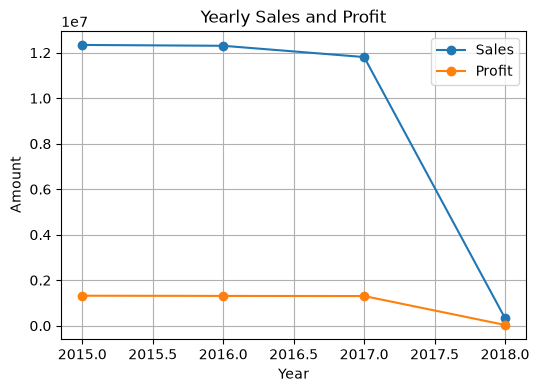

In [12]:
plt.figure(figsize=(6, 4))

plt.plot(
    yearly_performance["order year"],
    yearly_performance["Total_sales"],
    marker="o",
    label="Sales"
)

plt.plot(
    yearly_performance["order year"],
    yearly_performance["Total_profit"],
    marker="o",
    label="Profit"
)

plt.title("Yearly Sales and Profit")
plt.xlabel("Year")
plt.ylabel("Amount")
plt.legend()
plt.grid(True)
plt.show()

### Key Insight

Sales and profit remained relatively stable from 2015 to 2017. The apparent decline in 2018 is primarily due to the dataset containing substantially fewer records for that year, indicating that 2018 is likely an incomplete period. Therefore, 2018 should not be directly compared with the full previous years.

In [13]:
monthly_performance = df.groupby(
    ["order year", "order month"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Order Profit Per Order", "sum")
).reset_index()

In [14]:
monthly_performance.head(15)

,order year,order month,Total_Sales,Total_Profit
0,2015,1,1.051590e+06,111660.740132
1,2015,2,9.270099e+05,99140.660196
2,2015,3,1.051254e+06,113778.210191
3,2015,4,1.014463e+06,108083.679957
4,2015,5,1.050478e+06,112147.900143
5,2015,6,1.024006e+06,110147.160313
6,2015,7,1.038081e+06,115624.059879
7,2015,8,1.029495e+06,117979.770302
8,2015,9,1.018339e+06,113467.940118
9,2015,10,1.049154e+06,101757.870040


In [15]:
monthly_sales = df.groupby("order month")['Sales'].sum()
monthly_sales

order month
1     3.459246e+06
2     2.888088e+06
3     3.125112e+06
4     3.053996e+06
5     3.185364e+06
6     3.059152e+06
7     3.188170e+06
8     3.187032e+06
9     3.164511e+06
10    3.171279e+06
11    2.703625e+06
12    2.599160e+06
Name: Sales, dtype: float64

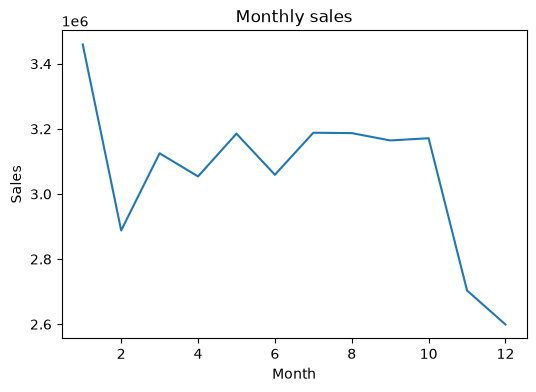

In [54]:
monthly_sales.plot(kind="line",figsize=(6,4))
plt.title("Monthly sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()

## Monthly Sales Analysis

Monthly sales were analyzed to identify recurring sales patterns across the available data.

January recorded the highest total sales at approximately **$3.46 million**, while December recorded the lowest at approximately **$2.60 million**. Sales remained relatively stable from March through October, followed by a decline during November and December.

This represents the historical monthly pattern in the dataset and should not be interpreted as a current-year trend.

In [18]:
monthly_profit = df.groupby("order month")['Order Profit Per Order'].sum()
monthly_profit

order month
1     367127.430615
2     301061.220935
3     333727.100652
4     339021.360056
5     337878.660269
6     324742.520726
7     348592.480100
8     360210.470630
9     359315.040248
10    331987.009971
11    281757.810287
12    281481.869563
Name: Order Profit Per Order, dtype: float64

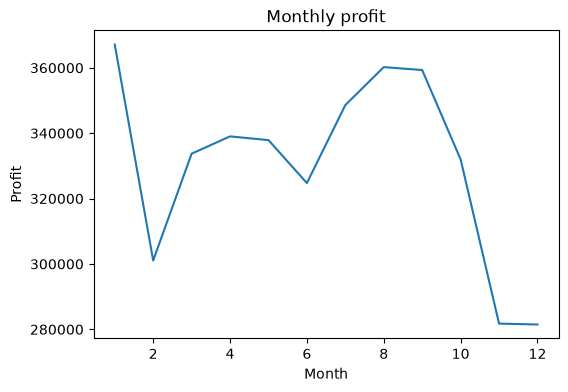

In [55]:
monthly_profit.plot(kind="line",figsize=(6,4))
plt.title("Monthly profit")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.show()

### Monthly Profit Analysis

Monthly profit was analyzed to identify recurring profitability patterns across the available data.

January generated the highest total profit at approximately **$367K**, while December recorded the lowest at approximately **$281K**. Profit generally follows the sales pattern, with stronger performance during the middle months and a decline during November and December.

In [26]:
market_performance = df.groupby("Market").agg(
    Total_sales=("Sales", "sum"),
    Total_Profit=("Order Profit Per Order", "sum")
).sort_values("Total_sales", ascending=False)

market_performance

,Total_sales,Total_Profit
Market,,
Europe,1.087240e+07,1.169443e+06
LATAM,1.027761e+07,1.123322e+06
Pacific Asia,8.273744e+06,8.577534e+05
USCA,5.066529e+06,5.643138e+05
Africa,2.294453e+06,2.520712e+05


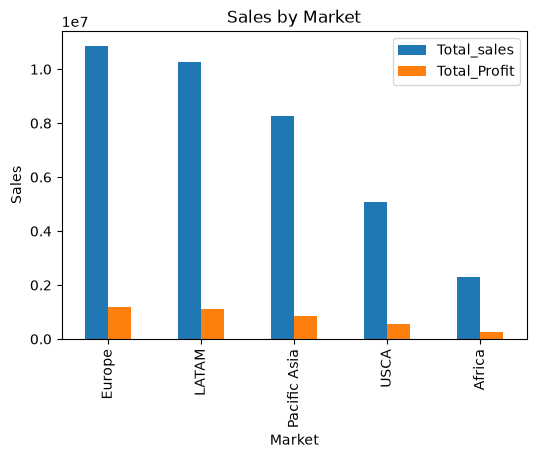

In [57]:
market_performance.plot(kind="bar",figsize=(6,4))
plt.title("Sales by Market")
plt.xlabel("Market")
plt.ylabel("Sales")
plt.show()

### Market Performance Insight

Europe is the strongest market in terms of both sales and total profit, followed closely by LATAM. Pacific Asia ranks third, while Africa has the lowest overall sales and profit.

The results indicate that Europe and LATAM are the major revenue and profit contributors in the dataset.

In [28]:
category_performance = df.groupby("Category Name").agg(
    Total_sales=("Sales", "sum"),
    Total_Profit=("Order Profit Per Order", "sum")
).sort_values("Total_sales", ascending=False)

category_performance.head(10)

,Total_sales,Total_Profit
Category Name,,
Fishing,6.929654e+06,756220.767190
Cleats,4.431943e+06,494636.919791
Camping & Hiking,4.118426e+06,427455.568106
Cardio Equipment,3.694843e+06,383011.098485
Women's Apparel,3.147800e+06,350421.029567
Water Sports,3.113845e+06,325146.960038
Men's Footwear,2.891758e+06,311902.820214
Indoor/Outdoor Games,2.888994e+06,318451.430554
Shop By Sport,1.309522e+06,129813.960315


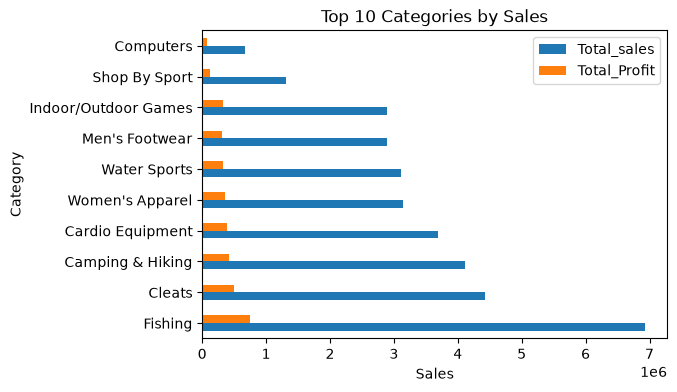

In [31]:
category_performance.head(10).plot(
    kind="barh",
    figsize=(6,4)
)

plt.title("Top 10 Categories by Sales")
plt.xlabel("Sales")
plt.ylabel("Category")
plt.show()

### Key Insight

Fishing is the highest-performing category, generating approximately **$6.93 million in sales** and **$756K in profit**. Cleats and Camping & Hiking follow as the next strongest categories.

The leading categories are largely sports and outdoor-related products, indicating that these categories are major contributors to overall business performance.

In [34]:
delivery_performance = df['Delivery Status'].value_counts()
delivery_performance

Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

In [35]:
late_delivery_rate = (
    (df["Delivery Status"] == "Late delivery").sum()
    / len(df)
) * 100

print("Late Delivery Rate:", late_delivery_rate)

Late Delivery Rate: 54.82913155955883


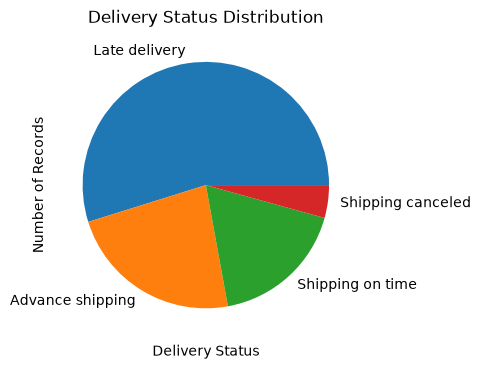

In [58]:
delivery_performance.plot(kind="pie", figsize=(6,4))

plt.title("Delivery Status Distribution")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

### Delivery Performance

The dataset shows a **54.83% late delivery rate**, with 98,977 records classified as late deliveries out of 180,519 records.

This indicates that late delivery is a significant supply-chain issue and should be investigated further to identify the markets, shipping modes, or categories associated with higher delays.

In [37]:
shipping_late_rate = df.groupby("Shipping Mode")["Late_delivery_risk"].mean() * 100

shipping_late_rate.sort_values(ascending=False)

Shipping Mode
First Class       95.322499
Second Class      76.632781
Same Day          45.743042
Standard Class    38.071683
Name: Late_delivery_risk, dtype: float64

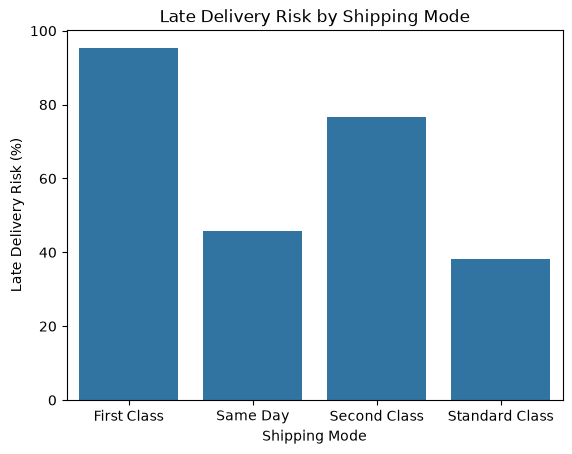

In [62]:
import seaborn as sns
sns.barplot(
    x=shipping_late_rate.index,
    y=shipping_late_rate.values
)

plt.title("Late Delivery Risk by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late Delivery Risk (%)")
plt.xticks(rotation=0)
plt.show()

### Shipping Mode and Delivery Risk

Late-delivery risk was compared across shipping modes to identify potential operational issues.

**First Class** has the highest late-delivery risk at approximately **95.32%**, followed by **Second Class at 76.63%**. Same Day and Standard Class have lower recorded risks of approximately **45.74%** and **38.07%**, respectively.

The results indicate that First Class and Second Class shipments require further investigation. However, the analysis shows an association rather than proving that the shipping mode itself causes delays.

In [40]:
segment_performance = df.groupby("Customer Segment").agg(
    Total_sales=("Sales", "sum"),
    Total_Profit=("Order Profit Per Order", "sum")
).sort_values("Total_sales", ascending=False)

segment_performance

,Total_sales,Total_Profit
Customer Segment,,
Consumer,1.909579e+07,2.073488e+06
Corporate,1.116841e+07,1.202575e+06
Home Office,6.520538e+06,6.908403e+05


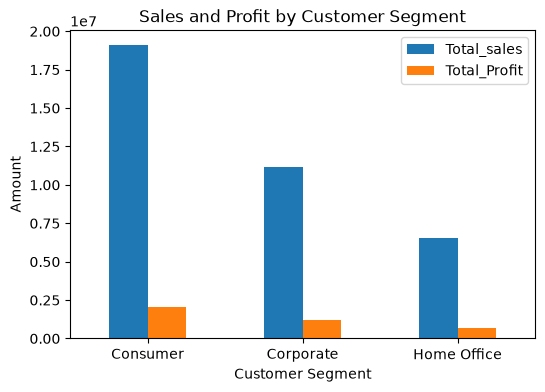

In [41]:
segment_performance.plot(
    kind="bar",
    figsize=(6,4)
)

plt.title("Sales and Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.show()

### Customer Segment Insight

The **Consumer segment** is the largest contributor, generating approximately **$19.10 million in sales** and **$2.07 million in profit**.

The Corporate segment follows with approximately **$11.17 million in sales**, while Home Office contributes approximately **$6.52 million**.

Overall, Consumer customers are the primary source of both sales and profit in the dataset.

In [44]:
negative_profit_count = (df["Order Profit Per Order"] < 0).sum()

print("Negative Profit Records:", negative_profit_count)



Negative Profit Records: 33784


In [45]:
negative_profit_percentage = (
    negative_profit_count / len(df)
) * 100

print("Negative Profit Percentage:", negative_profit_percentage)

Negative Profit Percentage: 18.714927514555253


In [46]:
loss_by_category = df[
    df["Order Profit Per Order"] < 0
].groupby("Category Name").size().sort_values(ascending=False)

loss_by_category.head(10)

Category Name
Cleats                  4590
Men's Footwear          4169
Women's Apparel         3923
Indoor/Outdoor Games    3617
Fishing                 3209
Water Sports            2924
Camping & Hiking        2590
Cardio Equipment        2332
Shop By Sport           2154
Electronics              562
dtype: int64

### Loss-Making Categories

Loss-making records were analyzed by product category to identify categories requiring further profitability investigation.

**Cleats** has the highest number of loss-making records at **4,590**, followed by **Men's Footwear (4,169)** and **Women's Apparel (3,923)**.

Some high-sales categories, such as Cleats and Fishing, also have a significant number of loss-making records. This indicates that high sales volume does not necessarily translate into profitability for every order.

In [47]:
top_products = df.groupby("Product Name").agg(
    Total_sales=("Sales", "sum"),
    Total_Profit=("Order Profit Per Order", "sum")
).sort_values("Total_sales", ascending=False)

top_products.head(10)

,Total_sales,Total_Profit
Product Name,,
Field & Stream Sportsman 16 Gun Fire Safe,6.929654e+06,756220.767190
Perfect Fitness Perfect Rip Deck,4.421143e+06,493828.299782
Diamondback Women's Serene Classic Comfort Bi,4.118426e+06,427455.568106
Nike Men's Free 5.0+ Running Shoe,3.667633e+06,379915.818503
Nike Men's Dri-FIT Victory Golf Polo,3.147800e+06,350421.029567
Pelican Sunstream 100 Kayak,3.099845e+06,324076.370020
Nike Men's CJ Elite 2 TD Football Cleat,2.891758e+06,311902.820214
O'Brien Men's Neoprene Life Vest,2.888994e+06,318451.430554
Under Armour Girls' Toddler Spine Surge Runni,1.269083e+06,126278.510299


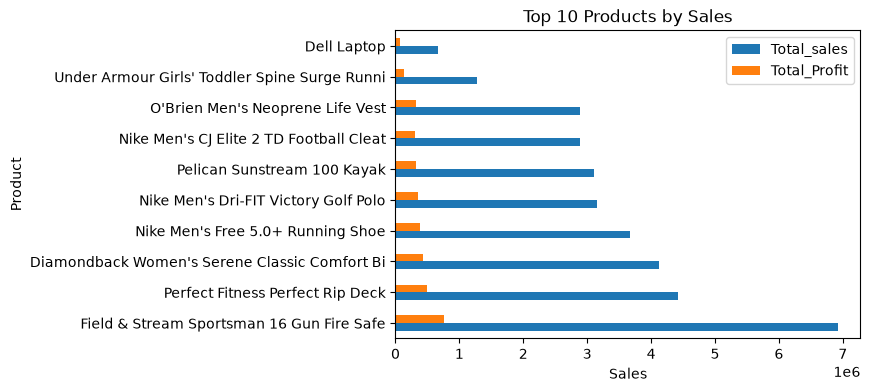

In [49]:
top_products.head(10).plot(
    kind="barh",
    figsize=(6,4)
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.ylabel("Product")
plt.show()

## Top Product Performance

Product-level sales and profit were analyzed to identify the highest-performing products.

The **Field & Stream Sportsman 16 Gun Fire Safe** is the top product by sales, generating approximately **$6.93 million in sales** and **$756K in profit**. It is followed by the **Perfect Fitness Perfect Rip Deck** and **Diamondback Women's Serene Classic Comfort Bike**.

The results show that a small group of products contributes significantly to overall sales and profit.

In [50]:
category_performance["Profit_Margin"] = (
    category_performance["Total_Profit"] /
    category_performance["Total_sales"]
) * 100

category_performance.sort_values(
    "Profit_Margin",
    ascending=False
).head(10)

,Total_sales,Total_Profit,Profit_Margin
Category Name,,,
Golf Bags & Carts,10369.390336,1810.069992,17.455896
Fitness Accessories,35601.440544,5258.390016,14.770161
Toys,6104.659979,900.710000,14.754466
Soccer,26477.049837,3901.949953,14.737102
Women's Clothing,140283.004745,19102.849930,13.617366
Baseball & Softball,94057.152543,12762.130067,13.568484
Garden,257768.728276,33443.010106,12.974037
Tennis & Racquet,44585.090624,5747.979996,12.892157
Music,113122.097353,14436.319923,12.761715


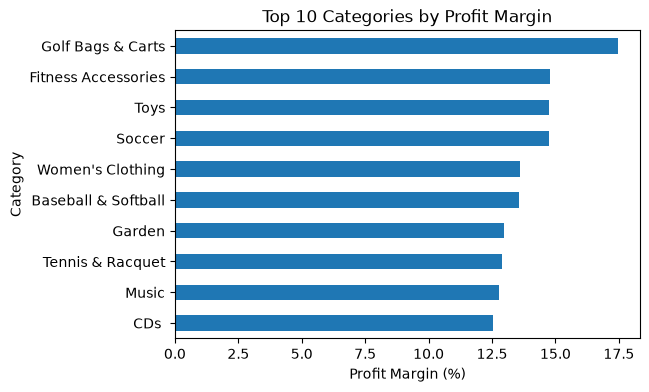

In [51]:
category_performance.sort_values(
    "Profit_Margin",
    ascending=False
).head(10)["Profit_Margin"].sort_values().plot(
    kind="barh",
    figsize=(6,4)
)

plt.title("Top 10 Categories by Profit Margin")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Category")
plt.show()

### Profit Margin by Category

Profit margin was calculated for each product category to compare profitability relative to sales.

**Golf Bags & Carts** has the highest profit margin at approximately **17.46%**, followed by Fitness Accessories, Toys, and Soccer.

The analysis shows that the categories generating the highest sales are not necessarily the categories with the highest profit margins. This highlights the importance of evaluating both sales volume and profitability.

In [52]:
market_delivery = df.groupby("Market")["Late_delivery_risk"].mean() * 100

market_delivery.sort_values(ascending=False)

Market
Europe          55.207753
Pacific Asia    55.046049
USCA            54.800574
Africa          54.589289
LATAM           54.355158
Name: Late_delivery_risk, dtype: float64

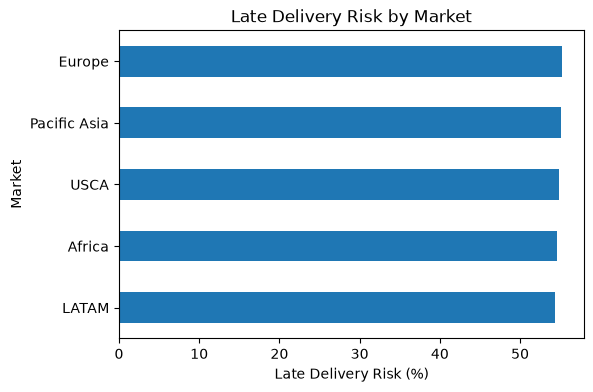

In [53]:
market_delivery.sort_values().plot(
    kind="barh",
    figsize=(6,4)
)

plt.title("Late Delivery Risk by Market")
plt.xlabel("Late Delivery Risk (%)")
plt.ylabel("Market")
plt.show()

## Numerical Distribution Analysis

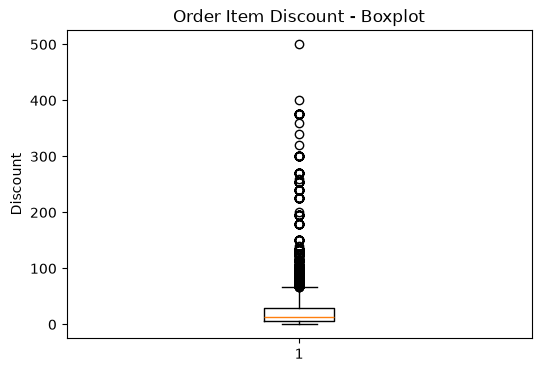

In [61]:
plt.figure(figsize=(6,4))

plt.boxplot(df["Order Item Discount"])

plt.title("Order Item Discount - Boxplot")
plt.ylabel("Discount")

plt.show()

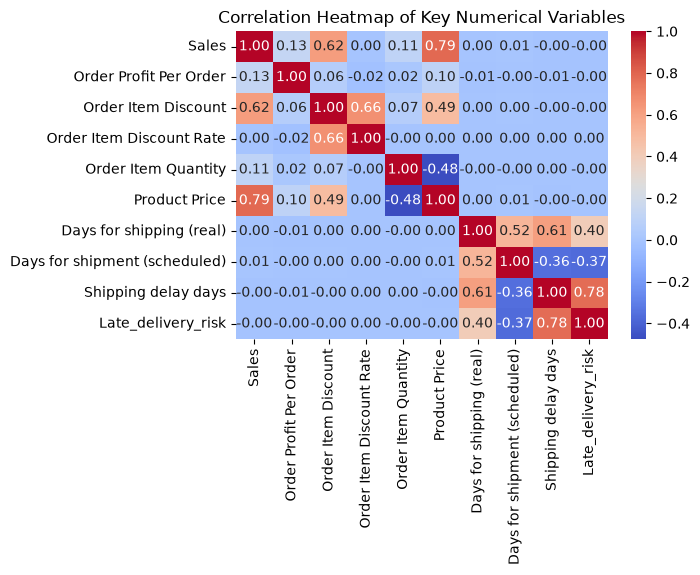

In [65]:


numeric_cols = [
    "Sales",
    "Order Profit Per Order",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Quantity",
    "Product Price",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Shipping delay days",
    "Late_delivery_risk"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(6,4))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Key Numerical Variables")
plt.show()